# Resource estimation for the 2D Fermi-Hubbard model

This notebook estimates QPE resource costs for one periodic two-dimensional
Fermi-Hubbard lattice, using the plaquette Trotterization of the time evolution. It does
not include the cost of preparing the initial state.
See [`extended_hubbard.ipynb`](../extended_hubbard.ipynb) for more details on the model Hamiltonian.

It has two halves:

1. a **logical** resource count for the lattice size set by `EXAMPLE_SIZE`
2. a **physical** estimate for that same lattice, which maps those logical counts onto a
   fault-tolerant architecture and reports physical qubits and runtime.

## Background: the 2D Fermi-Hubbard model

The Fermi-Hubbard Hamiltonian on a square lattice is

$$
H = -t \sum_{\langle i,j \rangle, \sigma} \left( c^\dagger_{i\sigma} c_{j\sigma} + \text{h.c.} \right)
  + U \sum_i n_{i\uparrow} n_{i\downarrow},
$$

a nearest-neighbour hopping term of amplitude $t$ and an on-site repulsion $U$. 
Each site carries two spin orbitals, so an $L \times L$ lattice needs $2L^2$ qubits under the Jordan-Wigner mapping.

We take $U = 8t$, the strong-coupling regime. The lattice is periodic in both directions.

We allow

$$
\epsilon_{\text{total}} = 0.0051 \ \text{per site},
$$

For the lattice selected by `EXAMPLE_SIZE`, this per-site budget is multiplied by $L^2$. We allocate a fraction (f=2/3) to phase estimation and the remaining (1/3) to Trotter error. Gate synthesis sits outside this energy budget: the physical estimate below fixes the number of T states per rotation and, separately, caps the probability that the whole computation fails at `MAX_ERROR = 0.01`.

In [1]:
import math

from qdk import qsharp
from qdk_chemistry.algorithms import create
from qdk_chemistry.algorithms.state_preparation import identity_state_prep
from qdk_chemistry.data import AlgorithmRef, FermiHubbardModelHamiltonianDescription, LatticeGeometry
from qdk_chemistry.utils import Logger

# Silence the library logs so the tables below stay readable.
Logger.set_global_level(Logger.LogLevel.off)

#: Hopping amplitude, which sets the unit of energy.
HOPPING_T = 1.0

#: U = 8t for the strong-coupling regime.
U_OVER_T = 8.0

#: Energy-error budget per site, split between phase estimation and Trotter error.
TARGET_PRECISION_PER_SITE = 0.0051

#: Number of phase qubits in QPE.
QPE_PRECISION_BITS = 10

#: Share of the energy budget allocated to phase estimation. Minimizing the total Trotter
#: step count sum_k r_k, which scales as 1 / (f * sqrt(1 - f)) in the phase-estimation
#: share f, gives f = 2/3. Same optimum used in Campbell (arXiv:2012.09238v4, App. F).
QPE_BUDGET_FRACTION = 2.0 / 3.0

#: Plaquette Trotter order.
TROTTER_ORDER = 2

## Evolution time of each phase-estimation query

The phase register starts in a **sine window**, whose phase estimate over $N = 2^b - 1$
queries has spread $\tan(\pi / (N + 2))$, a constant factor better than a uniform window.
Setting it equal to $\epsilon_{\text{QPE}} \cdot \tau$ fixes the base evolution time.

Bit $k$ then evolves for `base_time` $\cdot\, 2^k$ in a single block (the `"rescale"` power
strategy), with the Trotter step count re-derived for each time. This is far cheaper than
repeating the block $2^k$ times.

In [2]:
EXAMPLE_SIZE = 4


def evolution_schedule(size):
    """Return the energy budgets and the base evolution time for one lattice size."""
    num_sites = size * size
    energy_budget = TARGET_PRECISION_PER_SITE * num_sites
    qpe_budget = QPE_BUDGET_FRACTION * energy_budget
    trotter_budget = energy_budget - qpe_budget
    # A sine-windowed QPE phase state of N = 2^bits - 1 queries has spread
    # tan(pi / (N + 2)), which equals the required eps_QPE * tau.
    base_time = math.tan(math.pi / (2**QPE_PRECISION_BITS - 1 + 2)) / qpe_budget
    return energy_budget, qpe_budget, trotter_budget, base_time


energy_budget, qpe_budget, trotter_budget, base_time = evolution_schedule(EXAMPLE_SIZE)

## Building the time-evolution circuit

The evolution uses the **plaquette Trotterization**: the lattice is tiled twice into "pink"
and "gold" plaquettes, each plaquette is rotated into the momentum basis by a fermionic FFT,
and the hopping term becomes diagonal there.

Every layer ends up as a batch of **same-angle** $R_z$ rotations, which is phased through a
Hamming-weight register instead of term by term: an adder tree
compresses $n$ same-angle rotations into a $\log_2 n$-bit weight, which is added into a
catalyst prepared once per angle, so only one rotation per batch is applied. This is the
construction of [Kan and Symons (2025)](https://doi.org/10.1038/s41534-025-01091-0).

In [3]:
lattice = LatticeGeometry.square(
    EXAMPLE_SIZE, EXAMPLE_SIZE, periodic_x=True, periodic_y=True
)
model = FermiHubbardModelHamiltonianDescription(lattice, t=HOPPING_T, u=U_OVER_T * HOPPING_T)
#: Two spin orbitals per site under the Jordan-Wigner mapping.
num_system_qubits = 2 * lattice.num_sites

unitary_builder = AlgorithmRef(
    "hamiltonian_unitary_builder",
    "hubbard_plaquette",
    order=TROTTER_ORDER,
    time=base_time,
    # Bit k evolves for base_time * 2^k rather than repeating the block 2^k times.
    power_strategy="rescale",
    target_accuracy=trotter_budget,
)
circuit_builder = create(
    "qpe_circuit_builder",
    "qdk_standard",
    num_bits=QPE_PRECISION_BITS,
    unitary_builder=unitary_builder,
    controlled_circuit_mapper=AlgorithmRef(
        "controlled_circuit_mapper", "hubbard_plaquette"
    ),
)
circuit_builder.settings().set("phase_state", "sine")

state_prep = identity_state_prep(num_qubits=num_system_qubits)
circuit = circuit_builder.run(state_prep, model)[0]

## Counting the logical resources

`logical_counts` traces the emitted Q# program and returns the gate counts without
simulating it.

In [4]:
qsharp_factory = circuit._qsharp_factory
if qsharp_factory is None:
    raise RuntimeError("The QPE circuit does not have Q# factory data.")
qsharp_context = getattr(qsharp_factory.program, "_qdk_context", qsharp)
counts = dict(
    qsharp_context.logical_counts(
        qsharp_factory.program,
        *qsharp_factory.parameter.values(),
    )
)
counts

{'numQubits': 78,
 'tCount': 758427,
 'rotationCount': 24553,
 'rotationDepth': 24274,
 'cczCount': 592250,
 'ccixCount': 0,
 'measurementCount': 592260}

## Physical resource estimation

The logical counts above say nothing about wall-clock time or physical qubit count. To get
those we map the circuit onto a concrete fault-tolerant architecture: a Majorana qubit with
a $10^{-5}$ physical error rate, error-corrected with a three-auxiliary code, running
lattice surgery, and fed by round-based magic-state factories.

The sweep matches [`estimation_spin_liquids.ipynb`](estimation_spin_liquids.ipynb): 20 to 44
T gates per synthesized rotation, and lattice-surgery slow-down factors from 1 to 19, which
trade a longer runtime for fewer magic-state factories.

In [5]:
from qdk.qre import LatticeSurgery, PSSPC, estimate, plot_estimates
from qdk.qre.instruction_ids import LATTICE_SURGERY
from qdk.qre.models import Majorana, RoundBasedFactory, ThreeAux
from qdk.qre.property_keys import DISTANCE, NUM_TS_PER_ROTATION

#: Majorana qubit at a 1e-5 physical error rate.
ARCHITECTURE = Majorana(error_rate=1e-5)

#: Total failure probability allowed for the whole algorithm.
MAX_ERROR = 0.01

#: Rotation-synthesis precisions to sweep, in T gates per rotation.
TS_PER_ROTATION_SWEEP = list(range(20, 45, 2))

#: Lattice-surgery slow-down factors to sweep.
SLOW_DOWN_SWEEP = [1.0 * j for j in range(1, 20)]

application = circuit.get_qre_application()

trace_query = (
    application.q()
    * PSSPC.q(num_ts_per_rotation=TS_PER_ROTATION_SWEEP)
    * LatticeSurgery.q(slow_down_factor=SLOW_DOWN_SWEEP)
)
isa_query = ThreeAux.q() * RoundBasedFactory.q(code_query=ThreeAux.q())

estimates = estimate(
    application,
    ARCHITECTURE,
    isa_query,
    trace_query,
    max_error=MAX_ERROR,
    name=f"Hubbard {EXAMPLE_SIZE}x{EXAMPLE_SIZE}",
)
estimates.add_column("compute_distance", lambda entry: entry.source[LATTICE_SURGERY].instruction[DISTANCE])
estimates.add_column("num_ts_per_rotation", lambda entry: entry.properties[NUM_TS_PER_ROTATION])
estimates.add_qubit_partition_column()
estimates.add_factory_summary_column()
estimates.as_frame()

,name,qubits,runtime,error,compute_distance,num_ts_per_rotation,physical_compute_qubits,physical_factory_qubits,physical_memory_qubits,factories
0,Hubbard 4x4,37390,0 days 00:23:16.788480,0.007480,7,20,35126,2264,0,1×T
1,Hubbard 4x4,37903,0 days 00:21:16.751970,0.009790,7,20,35126,2777,0,1×T
2,Hubbard 4x4,38457,0 days 00:18:54.890640,0.009301,7,20,35126,3331,0,1×T
3,Hubbard 4x4,38970,0 days 00:17:27.591360,0.006957,7,20,35126,3844,0,1×T
4,Hubbard 4x4,39654,0 days 00:11:38.394240,0.006433,7,20,35126,4528,0,2×T
5,Hubbard 4x4,41788,0 days 00:09:27.445320,0.007344,7,20,35126,6662,0,2×T
6,Hubbard 4x4,41918,0 days 00:07:45.596160,0.006084,7,20,35126,6792,0,3×T
7,Hubbard 4x4,43457,0 days 00:07:05.583990,0.006854,7,20,35126,8331,0,3×T
8,Hubbard 4x4,44182,0 days 00:05:49.197120,0.005910,7,20,35126,9056,0,4×T
9,Hubbard 4x4,46446,0 days 00:04:43.722660,0.006365,7,20,35126,11320,0,5×T


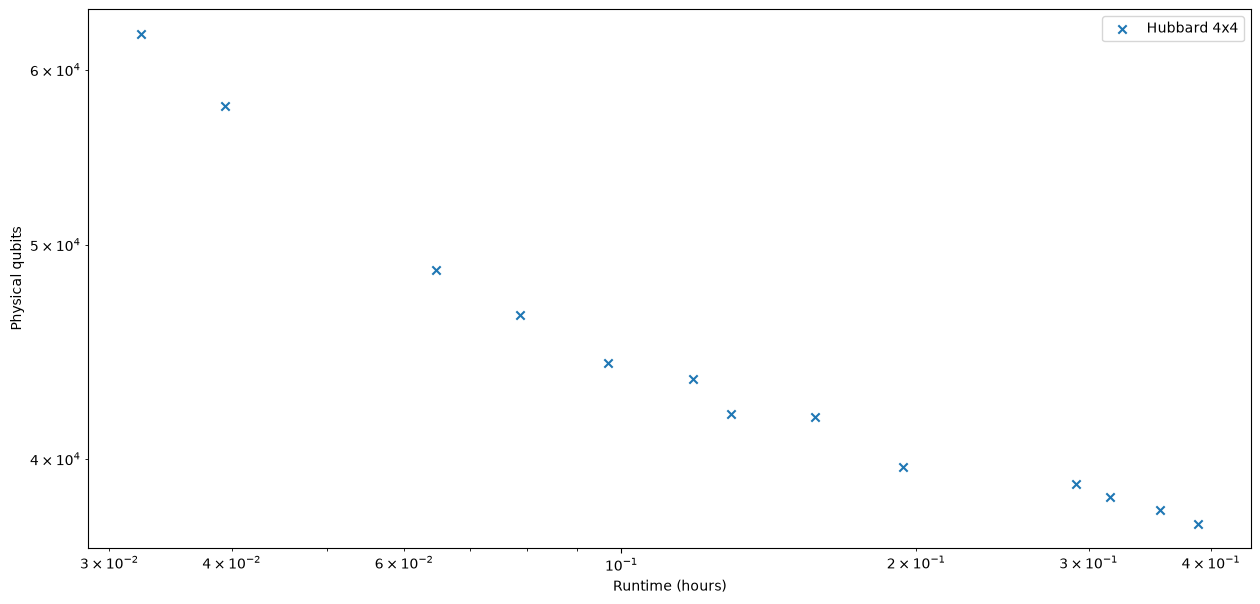

In [6]:
plot_estimates([estimates], runtime_unit="hours", figsize=(15, 7))